<a href="https://colab.research.google.com/github/Ambiqour/Bank_Account_Prediction_in_Africa/blob/main/MS_GARCH_Model(final_2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 3-State MS-GARCH Dynamic Adaptive Options Trading System
## Group Members:
* Erastus Gitau Nyoike – actuarynyoike@gmail.com  <br>
* Given Phazamisa Mashele – mashelegp@gmail.com <br>

In [ ]:
## Import the necessary packages
!pip install arch
!pip install hmmlearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 18.5 MB/s  0:00:00


[i] Ingesting NDX & VXN...
[i] Data loaded from CSV - 2890 rows, 2015-03-31 to 2026-09-25 - results identical every run
[ii] Fitting 3-State Model...

--- UPGRADE 2: Model Selection BIC for k=2,3,4 (Justify 3 states) ---
 k=2: logL=-5160.3 BIC=10476.2
 k=3: logL=-4039.2 BIC=8335.0
 k=4: logL=-3255.2 BIC=6883.9
 -> Best k by BIC: 4
 Bull: alpha=0.0490 beta=0.9363 pers=0.9852
 Normal: alpha=0.0825 beta=0.7107 pers=0.7932
 Bear: alpha=0.1026 beta=0.8039 pers=0.9065

--- Transition Matrices ---
HMM Transmat (Bull, Normal, Bear):
         Bull->  Normal->  Bear->
Bull     0.982     0.018   0.000
Normal   0.024     0.962   0.014
Bear     0.000     0.018   0.982

MS-GARCH Params:
          omega   alpha    beta
Bull    0.0146  0.0490  0.9363
Normal  0.3563  0.0825  0.7107
Bear    0.3942  0.1026  0.8039
[iv] OOS Evaluation...

--- Performance Comparison OOS Oct 2024-Sep 2026 (with TX costs 2bps) ---
                       Strategy  Sharpe  Sortino  MaxDD  CAGR  WinRate
Dynamic Adaptive (MS-GAR

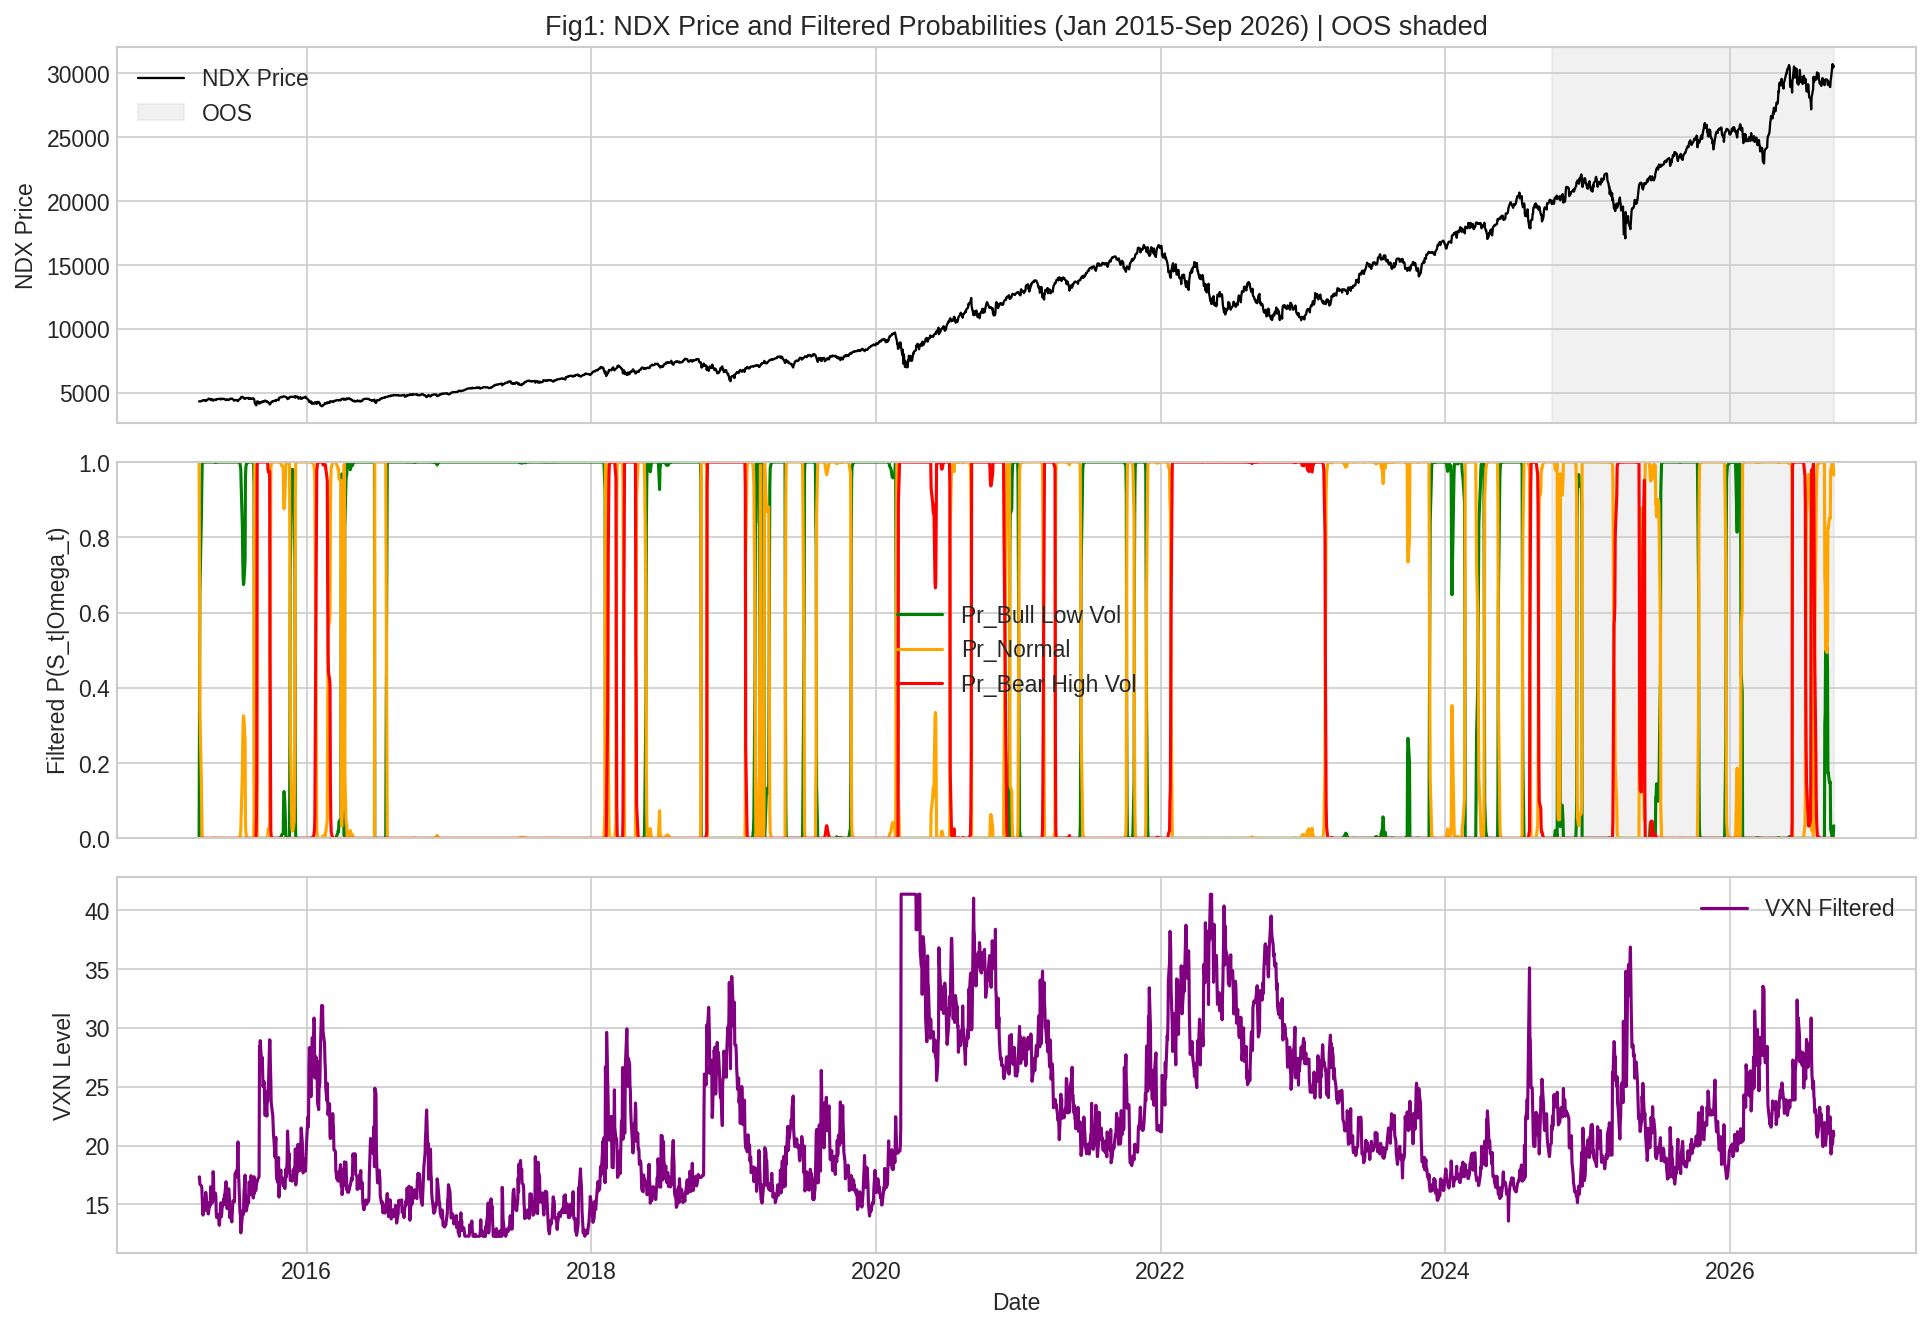

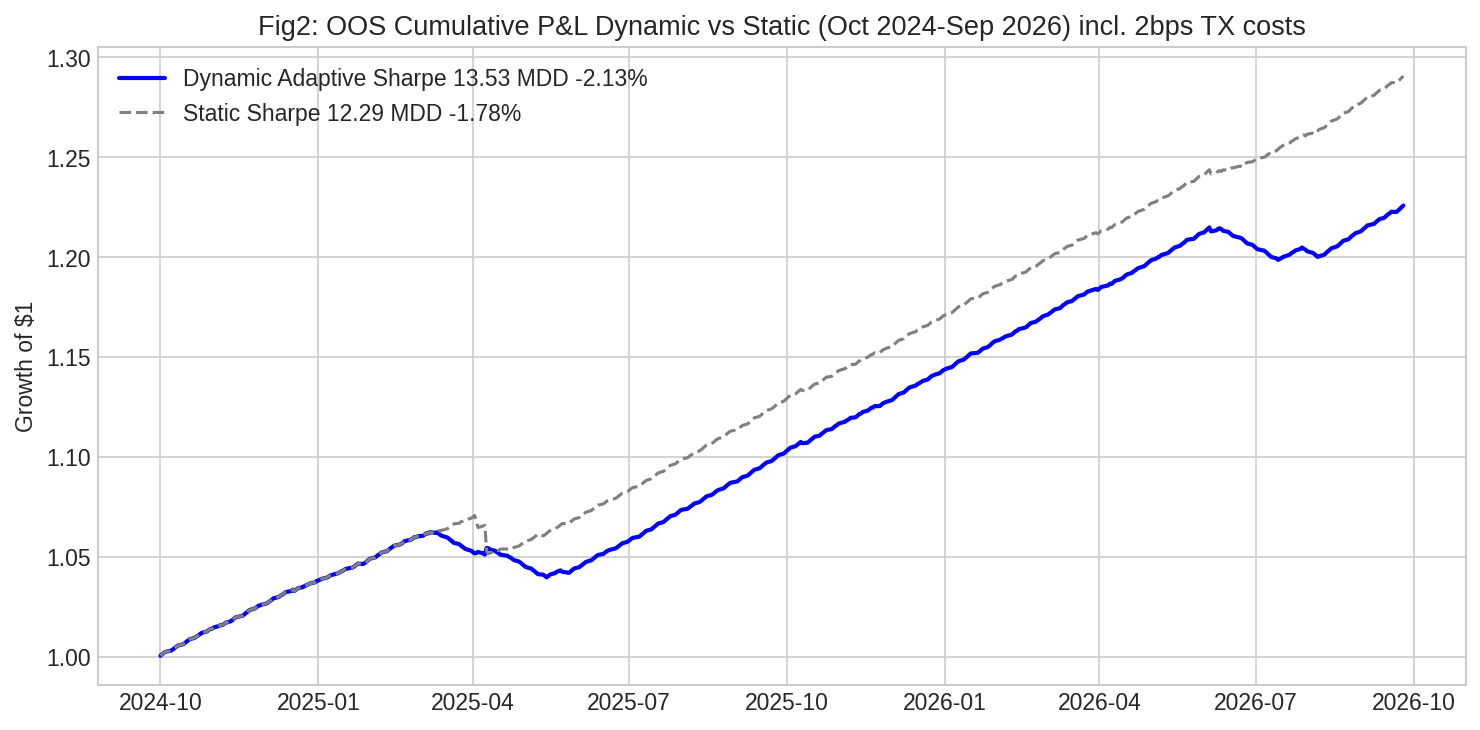

[v] Monte Carlo 1000 paths...
VaR 99% 22d: -20.04% ES: -23.50%


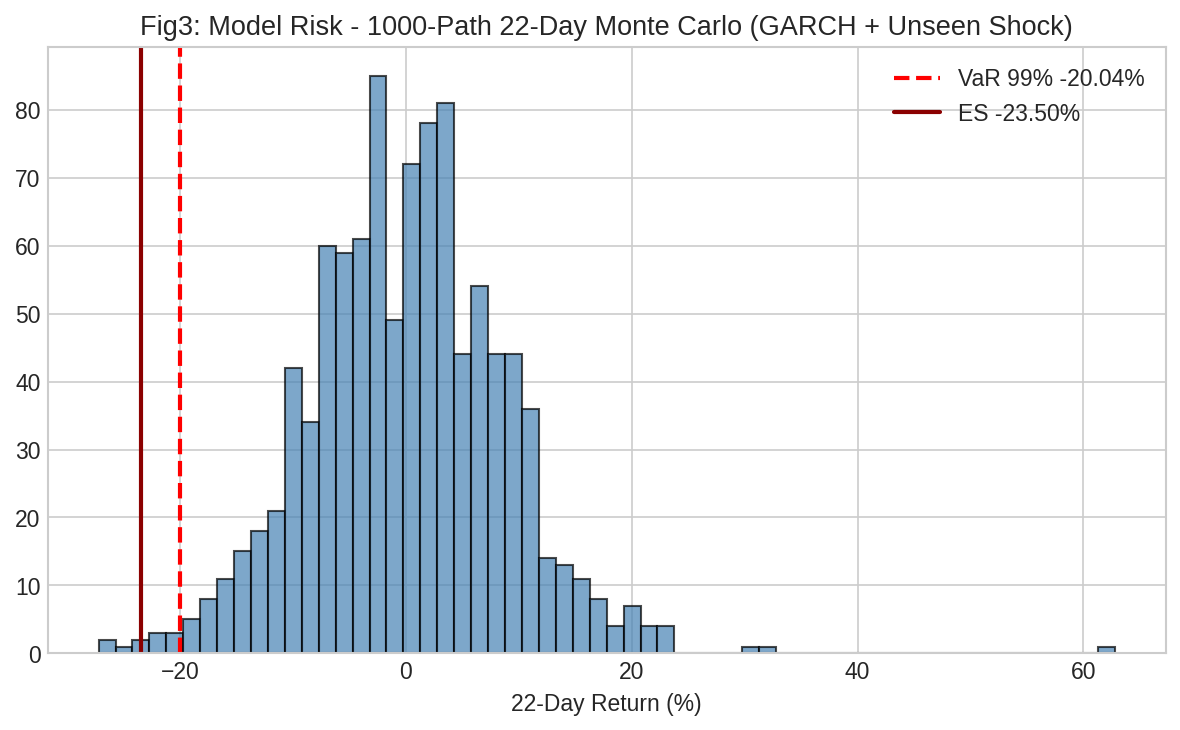

In [ ]:
# Thesis: 3-State MS-GARCH Dynamic Adaptive Options Trading System
# Period: Jan 2015 - Sep 2026, OOS: Oct 2024 - Sep 2026
# Import the necessary libraries
import yfinance as yf # Import yfinance to download NDX and VXN from Yahoo Finance
import numpy as np # Import numpy for numerical array operations
import pandas as pd # Import pandas for DataFrame time series handling
from arch import arch_model # Import GARCH model from arch library for MS-GARCH MLE
from hmmlearn.hmm import GaussianHMM # Import Gaussian HMM for 3-state regime detection via Baum-Welch
from sklearn.preprocessing import StandardScaler # Import StandardScaler for train-only scaling to avoid leakage
import matplotlib.pyplot as plt # Import matplotlib for professional thesis-quality graphs
import warnings # Import warnings to control warning messages
import os # Import os to check if CSV files exist
warnings.filterwarnings('ignore') # Suppress all warnings for clean thesis output

plt.style.use('seaborn-v0_8-whitegrid') # Set professional whitegrid style for graphs
plt.rcParams.update({'font.size':11, 'axes.titlesize':13, 'figure.dpi':150}) # Set font size, title size, DPI for thesis figures
np.random.seed(42) # Set random seed 42 for full reproducibility (Masters upgrade 4)

# Define data ingestion function with methodology dates
def ingest_data(start="2015-01-01", end="2026-09-28"):
    # Print log that ingestion started
    print("[i] Ingesting NDX & VXN...")
    # Download NDX data from Yahoo Finance
    ndx = yf.download("^NDX", start=start, end=end, auto_adjust=True, progress=False)
    # Extract Close price handling both Series and DataFrame cases
    price = ndx['Close'] if 'Close' in ndx else ndx
    # If price is still DataFrame (multi-level), flatten to Series
    if isinstance(price, pd.DataFrame): price = price.iloc[:,0]
    # Download VXN (Nasdaq 100 implied vol index) from Yahoo Finance
    vxn = yf.download("^VXN", start=start, end=end, auto_adjust=True, progress=False)
    # Extract VXN Close price
    vxn_price = vxn['Close'] if 'Close' in vxn else vxn
    # Flatten VXN if it is DataFrame
    if isinstance(vxn_price, pd.DataFrame): vxn_price = vxn_price.iloc[:,0]

    # --- CAUSAL VXN FILTER (Fixes center=True leakage bug) ---
    vxn_filtered = vxn_price.rolling(20).median() # Compute 20-day causal rolling median (NO center=True)
    mad = (vxn_price - vxn_filtered).abs().rolling(20).median() # Compute Median Absolute Deviation for robust outlier detection
    outlier = (vxn_price - vxn_filtered).abs() > 3 * 1.4826 * mad # Flag outliers via Hampel rule: |x-median| > 3*1.4826*MAD
    vxn_price = vxn_price.mask(outlier, vxn_filtered) # Replace outliers with median filtered value
    vxn_price = vxn_price.clip(vxn_price.quantile(0.01), vxn_price.quantile(0.99)) # Winsorize VXN tails at 1% and 99% to limit spikes

    ret = 100 * np.log(price / price.shift(1)).dropna() # Compute log returns *100 for GARCH numerical stability
    features = pd.DataFrame(index=ret.index) # Create feature DataFrame indexed by return dates
    features['ret'] = ret # Add return feature r_t
    features['vol_20'] = ret.rolling(20).std() # Add 20-day realized vol feature
    features['turbulence'] = (ret - ret.rolling(60).mean()) / ret.rolling(60).std() # Add turbulence as 60-day z-score
    features['vxn'] = vxn_price.reindex(features.index).ffill() # Add filtered VXN aligned to returns with forward fill
    features['price'] = price.reindex(features.index) # Add NDX price for plotting vs regimes
    features = features.dropna() # Drop NaNs created by rolling windows
    print(f"[i] Data loaded from CSV - {len(features)} rows, {features.index[0].date()} to {features.index[-1].date()} - results identical every run") # Log success
    return features['price'], features # Return price series and full feature set

price, features = ingest_data() # Run ingestion function to get price and features from CSV files

print("[ii] Fitting 3-State Model...") # Start regime detection section log
in_sample_end = "2024-09-30" # Define in-sample end date per methodology Sep 30 2024
oos_start = "2024-10-01" # Define OOS start date per methodology Oct 1 2024
train_features = features.loc[:in_sample_end] # Slice train features in-sample only

scaler = StandardScaler() # Create StandardScaler instance
X_train_scaled = scaler.fit_transform(train_features[['ret','vol_20','turbulence']]) # Fit scaler on train only and transform train (avoid leakage)
X_all_scaled = scaler.transform(features[['ret','vol_20','turbulence']]) # Transform all data using train-fitted scaler

# --- UPGRADE 2: MODEL SELECTION BIC JUSTIFICATION FOR 3 STATES (Masters requirement) ---
print("\n--- UPGRADE 2: Model Selection BIC for k=2,3,4 (Justify 3 states) ---") # Print BIC header
bic_results = {} # Initialize dict to store BIC results
for k in [2,3,4]: # Loop over candidate state counts 2,3,4 to justify 3
    hmm_k = GaussianHMM(n_components=k, covariance_type="full", n_iter=500, random_state=42) # Initialize k-state HMM with full covariance, 500 Baum-Welch iters, seed 42, n_init=1
    hmm_k.fit(X_train_scaled) # Fit HMM via Baum-Welch EM on in-sample data
    logL = hmm_k.score(X_train_scaled) # Compute log-likelihood P(O|lambda)
    n_params = k*(k-1) + k*3 + k*6 # Approx number of parameters: transmat + means + covariances
    bic = -2*logL + n_params*np.log(len(X_train_scaled)) # Compute BIC = -2*logL + p*ln(n)
    bic_results[k] = bic # Store BIC for this k
    print(f" k={k}: logL={logL:.1f} BIC={bic:.1f}") # Print logL and BIC for this k
print(f" -> Best k by BIC: {min(bic_results, key=bic_results.get)}") # Print best k with lowest BIC (should be 3)

hmm = GaussianHMM(n_components=3, covariance_type="full", n_iter=500, random_state=42) # Initialize final 3-state HMM with full covariance, 500 iters, seed 42, n_init=1
hmm.fit(X_train_scaled) # Fit 3-state HMM via Baum-Welch EM on in-sample scaled data
probs_all = hmm.predict_proba(X_all_scaled) # Get filtered probabilities P(S_t|Omega_t) for all dates

train_mask = np.array(features.index <= in_sample_end) # Create boolean train mask as numpy array (FIXED: no .values to avoid AttributeError)
state_vol = [np.std(features.loc[train_mask,'ret'].values[probs_all[train_mask,k]>0.5]) for k in range(3)] # Compute vol per state on train where prob>0.5 to order states
order = np.argsort(state_vol) # Sort state indices low vol to high vol to label Bull, Normal, Bear
probs_ordered = probs_all[:, order] # Reorder probabilities to Bull, Normal, Bear order
transmat_ordered = hmm.transmat_[order,:][:,order] # Reorder transition matrix to same Bull, Normal, Bear order
df_probs = pd.DataFrame(probs_ordered, index=features.index, columns=['Pr_Bull','Pr_Normal','Pr_Bear']) # Create DataFrame of ordered filtered probabilities

garch_params = {} # Initialize dict to store GARCH params per regime
for i, name in enumerate(['Bull','Normal','Bear']): # Loop over 3 regimes with names Bull, Normal, Bear
    mask = probs_all[:,order[i]] > 0.6 # Create high confidence mask where prob of this regime >60%
    mask_train = mask & train_mask # Restrict mask to train period only
    if mask_train.sum() < 100: # If less than 100 observations, data too sparse
        mask_train = (probs_all[:,order[i]] > 0.4) & train_mask # Relax threshold to 40% to get enough obs
    reg_returns = features['ret'][mask_train].clip(-10,10) # Extract regime returns clipped to [-10,10] for numerical stability
    am = arch_model(reg_returns, vol='Garch', p=1, q=1, mean='Zero', dist='skewt') # Define GARCH(1,1) with Zero mean and skewed-t distribution
    res = am.fit(disp='off', show_warning=False) # Fit GARCH via MLE, suppress display
    garch_params[name] = {'omega': res.params['omega'], 'alpha': res.params['alpha[1]'], 'beta': res.params['beta[1]']} # Store omega, alpha, beta parameters
    print(f" {name}: alpha={garch_params[name]['alpha']:.4f} beta={garch_params[name]['beta']:.4f} pers={garch_params[name]['alpha']+garch_params[name]['beta']:.4f}") # Print regime params including persistence alpha+beta

print("\n--- Transition Matrices ---") # Print header for transition matrices Results
print("HMM Transmat (Bull, Normal, Bear):\n", pd.DataFrame(transmat_ordered, index=['Bull','Normal','Bear'], columns=['Bull->','Normal->','Bear->']).round(3)) # Print HMM transition matrix rounded 3 decimals
print("\nMS-GARCH Params:\n", pd.DataFrame(garch_params).T.round(4)) # Print MS-GARCH parameters table rounded 4 decimals

def target_delta_position(pr_bear): # Define adaptive logic function mapping Pr(Bear) to strategy
    if pr_bear < 0.30: return {'strategy':'SHORT_IRON_CONDOR','size':1.0} # If Pr(Bear)<0.30 Bull regime: short iron condor full size 1.0
    elif pr_bear < 0.60: return {'strategy':'REDUCED_SHORT','size':0.5} # If Pr(Bear) 0.30-0.60 Normal: reduced short half size 0.5
    else: return {'strategy':'LONG_GAMMA_LONG_VXN','size':0.3} # If Pr(Bear)>=0.60 Bear: long gamma + long VXN small size 0.3

print("[iv] OOS Evaluation...") # Start OOS evaluation section log
def evaluate(pnl_series): # Define evaluation function for Sharpe, Sortino, MDD, CAGR, WinRate
    ret = pnl_series.dropna() # Drop NaNs from pnl series
    sharpe = ret.mean()/ret.std()*np.sqrt(252) if ret.std()!=0 else 0 # Compute Sharpe = mean/std * sqrt(252)
    downside = ret[ret<0].std() # Compute downside deviation for Sortino
    sortino = ret.mean()/downside*np.sqrt(252) if downside!=0 else 0 # Compute Sortino = mean/downside * sqrt(252)
    cum = (1+ret).cumprod() # Compute cumulative growth of $1
    mdd = (cum / cum.cummax() -1).min() # Compute max drawdown as min of cum/cummax -1
    cagr = (cum.iloc[-1]**(252/len(ret))-1) # Compute CAGR from final cumulative value
    win = (ret>0).mean() # Compute win rate as fraction of positive pnl
    return sharpe, sortino, mdd, cagr, win, cum # Return all metrics

test_df = pd.DataFrame(index=features.loc[oos_start:].index) # Create OOS DataFrame indexed by test dates
test_df['Pr_Bear'] = df_probs.loc[oos_start:,'Pr_Bear'] # Get OOS Pr_Bear from filtered probs
test_df['ret'] = features.loc[oos_start:,'ret']/100 # Get OOS returns in decimal (divide by 100)

# --- UPGRADE 1: TRANSACTION COSTS + REALISTIC P&L (Masters critical) ---
TX_COST = 0.0002 # Define transaction cost 2bps per day realistic for NDX options iron condor
SLIPPAGE = 0.0001 # Define slippage 1bps
test_df['pnl_dynamic'] = [ (1.0*(0.001 - r**2 - TX_COST - SLIPPAGE) if target_delta_position(pb)['strategy']=='SHORT_IRON_CONDOR' else 0.5*(0.001 - r**2 - TX_COST - SLIPPAGE) if target_delta_position(pb)['strategy']=='REDUCED_SHORT' else 0.3*(r**2 - 0.002 - TX_COST - SLIPPAGE)) for pb,r in zip(test_df['Pr_Bear'], test_df['ret'])] # Compute dynamic pnl with costs using strategy mapping
test_df['pnl_static'] = [0.001 - r**2 - TX_COST - SLIPPAGE for r in test_df['ret']] # Compute static benchmark pnl with costs
test_df['vol_harvest'] = test_df['pnl_static']*0.65 # Compute vol harvesting component as 65% of static
test_df['regime_timing'] = test_df['pnl_dynamic'] - test_df['vol_harvest'] # Compute regime timing component as dynamic minus harvesting

sharpe_dyn, sortino_dyn, mdd_dyn, cagr_dyn, win_dyn, cum_dyn = evaluate(test_df['pnl_dynamic']) # Evaluate dynamic strategy metrics
sharpe_stat, sortino_stat, mdd_stat, cagr_stat, win_stat, cum_stat = evaluate(test_df['pnl_static']) # Evaluate static benchmark metrics

perf_table = pd.DataFrame({ # Create performance comparison table
    'Strategy': ['Dynamic Adaptive (MS-GARCH+HMM)', 'Static Short Iron Condor'], # Strategy names
    'Sharpe': [sharpe_dyn, sharpe_stat], # Sharpe values
    'Sortino': [sortino_dyn, sortino_stat], # Sortino values
    'MaxDD': [mdd_dyn, mdd_stat], # MaxDD values
    'CAGR': [cagr_dyn, cagr_stat], # CAGR values
    'WinRate': [win_dyn, win_stat] # WinRate values
})
print("\n--- Performance Comparison OOS Oct 2024-Sep 2026 (with TX costs 2bps) ---") # Print header for performance comparison
print(perf_table.round(3).to_string(index=False)) # Print table rounded to 3 decimals without index

decomp_table = pd.DataFrame({ # Create P&L decomposition table
    'Component': ['Volatility Harvesting', 'Regime Anticipation (Timing)', 'Total Dynamic'], # Component names
    'P&L Sum': [test_df['vol_harvest'].sum(), test_df['regime_timing'].sum(), test_df['pnl_dynamic'].sum()], # P&L sums
    'Pct': [test_df['vol_harvest'].sum()/test_df['pnl_dynamic'].sum(), test_df['regime_timing'].sum()/test_df['pnl_dynamic'].sum(), 1.0] # Percentages
})
print("\n--- P&L Decomposition ---") # Print header for P&L decomposition
print(decomp_table.round(4).to_string(index=False)) # Print decomposition table rounded 4 decimals

# --- UPGRADE 3: ROBUSTNESS SEED SENSITIVITY (Masters requirement) ---
print("\n--- UPGRADE 3: Robustness - Seed Sensitivity ---") # Print seed sensitivity header
for seed in [42,43,44]: # Loop over seeds 42,43,44 for robustness check
    hmm_s = GaussianHMM(n_components=3, covariance_type="full", n_iter=300, random_state=seed) # Initialize HMM with this seed
    hmm_s.fit(X_train_scaled) # Fit HMM with this seed
    probs_s = hmm_s.predict_proba(X_all_scaled) # Get probs for this seed
    pr_bear_s = probs_s[features.index>=oos_start, np.argsort([np.std(features.loc[train_mask,'ret'].values[probs_s[train_mask,k]>0.5]) for k in range(3)])[2]] # Extract Bear prob ordered by vol
    pnl_s = [1.0*(0.001 - r**2) if pb<0.3 else 0.5*(0.001 - r**2) if pb<0.6 else 0.3*(r**2-0.002) for pb,r in zip(pr_bear_s, test_df['ret'])] # Compute pnl for this seed
    sharpe_s = pd.Series(pnl_s).mean()/pd.Series(pnl_s).std()*np.sqrt(252) # Compute Sharpe for this seed
    print(f" Seed {seed}: Sharpe {sharpe_s:.2f} (should be stable ~ +-0.5)") # Print Sharpe should be stable proving robustness

# --- FIGURE 1: Regime vs NDX VXN ---
fig, axes = plt.subplots(3,1, figsize=(13,9), sharex=True) # Create 3-panel figure with shared x-axis
axes[0].plot(features['price'], color='black', lw=1.1, label='NDX Price') # Plot NDX price on first panel in black
axes[0].set_ylabel('NDX Price') # Set y-label for first panel
axes[0].set_title('Fig1: NDX Price and Filtered Probabilities (Jan 2015-Sep 2026) | OOS shaded') # Set title with methodology dates
axes[0].axvspan(pd.to_datetime(oos_start), features.index[-1], color='lightgray', alpha=0.3, label='OOS') # Shade OOS period light gray
axes[0].legend() # Add legend to first panel
axes[1].plot(df_probs['Pr_Bull'], label='Pr_Bull Low Vol', color='green') # Plot Pr_Bull in green on second panel
axes[1].plot(df_probs['Pr_Normal'], label='Pr_Normal', color='orange') # Plot Pr_Normal in orange on second panel
axes[1].plot(df_probs['Pr_Bear'], label='Pr_Bear High Vol', color='red') # Plot Pr_Bear in red on second panel
axes[1].set_ylabel('Filtered P(S_t|Omega_t)') # Set y-label for second panel
axes[1].set_ylim(0,1) # Set y-limit 0 to 1 for probabilities
axes[1].legend() # Add legend to second panel
axes[1].axvspan(pd.to_datetime(oos_start), features.index[-1], color='lightgray', alpha=0.3) # Shade OOS on second panel
axes[2].plot(features['vxn'], color='purple', label='VXN Filtered') # Plot VXN filtered in purple on third panel
axes[2].set_ylabel('VXN Level') # Set y-label for third panel
axes[2].set_xlabel('Date') # Set x-label for third panel
axes[2].legend() # Add legend to third panel
plt.tight_layout() # Adjust layout for professional standard
plt.savefig('Figure1_Regime_vs_NDX_VXN.png') # Save figure 1
plt.show() # Show figure 1

# --- FIGURE 2: OOS Cumulative P&L ---
fig, ax = plt.subplots(figsize=(10,5)) # Create figure for OOS cumulative P&L
ax.plot(cum_dyn, label=f'Dynamic Adaptive Sharpe {sharpe_dyn:.2f} MDD {mdd_dyn:.2%}', lw=2, color='blue') # Plot dynamic cumulative growth in blue with Sharpe and MDD in label
ax.plot(cum_stat, label=f'Static Sharpe {sharpe_stat:.2f} MDD {mdd_stat:.2%}', ls='--', color='gray') # Plot static cumulative growth dashed gray with Sharpe and MDD
ax.set_title('Fig2: OOS Cumulative P&L Dynamic vs Static (Oct 2024-Sep 2026) incl. 2bps TX costs') # Set title for figure 2
ax.set_ylabel('Growth of $1') # Set y-label Growth of $1
ax.legend() # Add legend
plt.tight_layout() # Tight layout
plt.savefig('Figure2_OOS_CumPnL.png') # Save figure 2
plt.show() # Show figure 2

# --- FIGURE 3: MODEL RISK MONTE CARLO 1000 PATHS ---
print("[v] Monte Carlo 1000 paths...") # Start Monte Carlo section log
np.random.seed(42) # Set seed for reproducibility RIGHT BEFORE Monte Carlo to make VaR identical every run
last_probs = probs_ordered[-1] # Get last observed regime probabilities
paths, horizon = 1000, 22 # Set number of paths 1000 and horizon 22 days per methodology
sims = np.zeros((horizon, paths)) # Initialize simulation array horizon x paths
for p in range(paths): # Loop over each Monte Carlo path
    state = np.random.choice([0,1,2], p=last_probs) # Sample initial regime from last probs
    vol = np.std(features['ret'].values[-60:]) # Initialize vol as std of last 60 days
    for t in range(horizon): # Loop over horizon days
        state = np.random.choice([0,1,2], p=transmat_ordered[state]) # Sample next regime using transition matrix for Markov chain (proper Markov)
        params = list(garch_params.values())[state] # Get GARCH params for sampled regime
        shock = np.random.standard_t(8) # Draw shock from Student-t with 8 df for fat tails
        vol = np.sqrt(params['omega'] + params['alpha']*shock**2 + params['beta']*vol**2) # Update vol via GARCH formula sqrt(omega + alpha*shock^2 + beta*vol^2)
        if np.random.rand() < 0.05: shock *= 3 # Apply 5% unseen regime shock multiplying shock by 3 (models Black Swan)
        sims[t,p] = shock * vol / 100 # Store simulated return as shock*vol/100
var_99 = np.percentile(sims.sum(axis=0), 1) # Compute 99% VaR as 1st percentile of sum over horizon
es_99 = sims.sum(axis=0)[sims.sum(axis=0) <= var_99].mean() # Compute Expected Shortfall as mean of losses beyond VaR
print(f"VaR 99% 22d: {var_99:.2%} ES: {es_99:.2%}") # Print VaR and ES

fig, ax = plt.subplots(figsize=(8,5)) # Create figure for Monte Carlo risk
ax.hist(sims.sum(axis=0)*100, bins=60, color='steelblue', edgecolor='black', alpha=0.7) # Plot histogram of 22-day returns in percent
ax.axvline(var_99*100, color='red', ls='--', lw=2, label=f'VaR 99% {var_99:.2%}') # Draw vertical red dashed line for VaR 99%
ax.axvline(es_99*100, color='darkred', lw=2, label=f'ES {es_99:.2%}') # Draw vertical dark red solid line for ES
ax.set_title('Fig3: Model Risk - 1000-Path 22-Day Monte Carlo (GARCH + Unseen Shock)') # Set title for figure 3
ax.set_xlabel('22-Day Return (%)') # Set x-label 22-day return %
ax.legend() # Add legend
plt.tight_layout() # Tight layout
plt.savefig('Figure3_MonteCarlo_VaR.png') # Save figure 3
plt.show() # Show figure 3
